# Creating Graphs for each section

In [1]:
from pathlib import Path

import graphviz
import matplotlib.pyplot as plt

import numpy as np

from sklearn.datasets import make_blobs
from sklearn.neighbors import KDTree
from sklearn.cluster import KMeans


In [2]:
current_path = Path.cwd().resolve()
repository_root = next(
    (path for path in (current_path, *current_path.parents)
     if (path / 'latex').is_dir() and (path / 'resc-experiments').is_dir()),
    None,
)
if repository_root is None:
    raise RuntimeError('Could not locate repository root containing latex and resc-experiments')
FIGURES_PATH = repository_root / 'latex'

## Illustrative $k$-NN Weight-Variation Graph

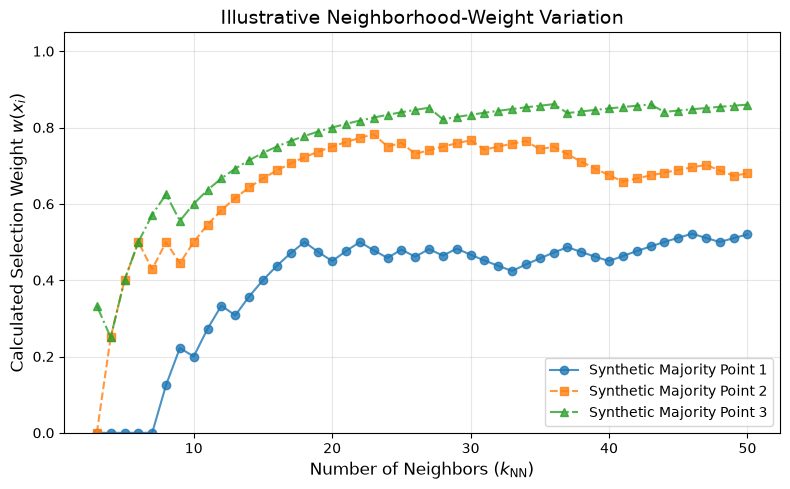

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.neighbors import KDTree

# 1. Generate synthetic imbalanced data with an overlapping region
X_maj, _ = make_blobs(n_samples=800, centers=[[0, 0]], cluster_std=1.5, random_state=42)
X_min, _ = make_blobs(n_samples=150, centers=[[1.5, 1.5]], cluster_std=1.2, random_state=42)
X = np.vstack([X_maj, X_min])
y = np.hstack([np.zeros(800), np.ones(150)])

# 2. Build spatial index for the entire dataset
tree = KDTree(X)

# 3. Identify observations with the largest within-example weight variation
k_values = list(range(3, 51))
majority_indices = np.where(y == 0)[0]

variation_scores = []
all_weights = {}

# Calculate weight histories for all majority observations
for idx in majority_indices:
    point = X[idx]
    weights = []
    
    # Query the max k needed once to optimize speed
    dist, ind = tree.query(point.reshape(1, -1), k=max(k_values) + 1)
    
    # Exclude the point itself (which is at ind[0][0])
    neighbors_y = y[ind[0][1:]] 
    
    for k in k_values:
        current_neighbors_y = neighbors_y[:k]
        # Calculate the proportion of neighbors belonging to the majority class
        weight = np.sum(current_neighbors_y == 0) / k
        weights.append(weight)
        
    all_weights[idx] = weights
    # Calculate within-example variation as neighborhood size changes
    variation_scores.append((idx, np.var(weights)))

# Sort by variance, largest first
variation_scores.sort(key=lambda x: x[1], reverse=True)

# Select the top three observations by across-k weight variance
top_3_indices = [variation_scores[0][0], variation_scores[1][0], variation_scores[2][0]]

# 4. Plot illustrative neighborhood-weight variation
plt.figure(figsize=(8, 5))
markers = ['o', 's', '^']
lines = ['-', '--', '-.']
labels = ['Synthetic Majority Point 1', 'Synthetic Majority Point 2', 'Synthetic Majority Point 3']

for i, idx in enumerate(top_3_indices):
    plt.plot(k_values, all_weights[idx], marker=markers[i], linestyle=lines[i], 
             label=labels[i], alpha=0.8)

plt.title("Illustrative Neighborhood-Weight Variation", fontsize=14)
plt.xlabel(r"Number of Neighbors ($k_{\mathrm{NN}}$)", fontsize=12)
plt.ylabel("Calculated Selection Weight $w(x_i)$", fontsize=12)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()

# Save for publication
plt.savefig(FIGURES_PATH / 'knn_volatility.pdf', format='pdf', dpi=300)
plt.show()

## Illustrative Spatial Quantization Comparison

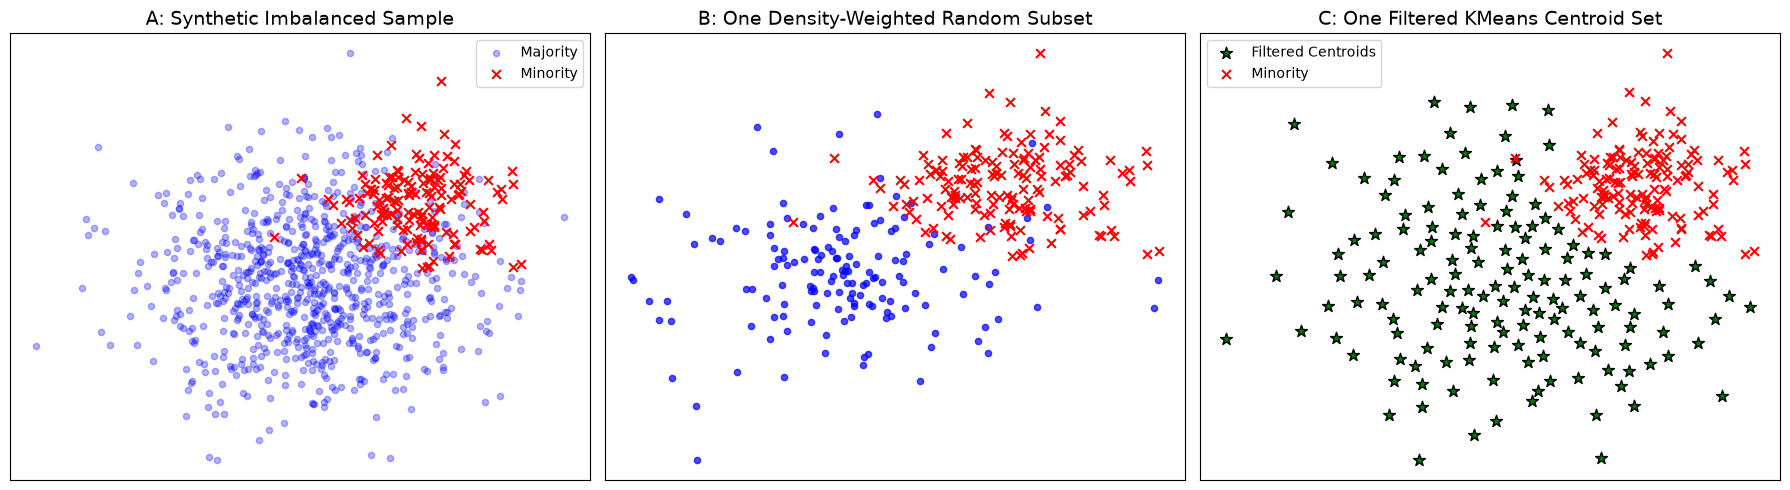

In [4]:


# 1. Generate synthetic data with overlapping clusters
X_maj, _ = make_blobs(n_samples=800, centers=[[0, 0]], cluster_std=1.5, random_state=42)
X_min, _ = make_blobs(n_samples=150, centers=[[2, 2]], cluster_std=0.8, random_state=42)
X_full = np.vstack([X_maj, X_min])
y_full = np.hstack([np.zeros(800), np.ones(150)])

# Shared illustrative representative count
target_size = 150 

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- PANEL A: Raw synthetic data ---
axes[0].scatter(X_maj[:, 0], X_maj[:, 1], c='blue', alpha=0.3, label='Majority', s=20)
axes[0].scatter(X_min[:, 0], X_min[:, 1], c='red', marker='x', label='Minority', s=40)
axes[0].set_title("A: Synthetic Imbalanced Sample", fontsize=14)
axes[0].legend()

# --- PANEL B: One custom density-weighted random subset ---
# Illustrative probability rule favoring points near the majority center
center_distances = np.linalg.norm(X_maj - [0, 0], axis=1)
probabilities = 1 / (center_distances + 0.1)
probabilities /= probabilities.sum()

rng = np.random.default_rng(42)
weighted_indices = rng.choice(len(X_maj), size=target_size, replace=False, p=probabilities)
X_maj_weighted = X_maj[weighted_indices]

axes[1].scatter(X_maj_weighted[:, 0], X_maj_weighted[:, 1], c='blue', alpha=0.7, label='Density-Weighted Subset', s=20)
axes[1].scatter(X_min[:, 0], X_min[:, 1], c='red', marker='x', label='Minority', s=40)
axes[1].set_title("B: One Density-Weighted Random Subset", fontsize=14)

# --- PANEL C: One filtered KMeans centroid collection ---
# Phase 1: k-NN Density Filter
tree = KDTree(X_full)
safe_indices = []
k_nn = 15
threshold = 0.9

for i, point in enumerate(X_maj):
    _, ind = tree.query(point.reshape(1, -1), k=k_nn)
    maj_ratio = np.sum(y_full[ind[0]] == 0) / k_nn
    if maj_ratio >= threshold:
        safe_indices.append(i)

X_safe = X_maj[safe_indices]

# Phase 2: k-means Centroid Extraction
kmeans = KMeans(n_clusters=target_size, random_state=42, n_init=10)
kmeans.fit(X_safe)
X_centroids = kmeans.cluster_centers_

axes[2].scatter(X_centroids[:, 0], X_centroids[:, 1], c='green', marker='*', s=80, label='Filtered Centroids', edgecolor='black')
axes[2].scatter(X_min[:, 0], X_min[:, 1], c='red', marker='x', label='Minority', s=40)
axes[2].set_title("C: One Filtered KMeans Centroid Set", fontsize=14)
axes[2].legend()

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig(FIGURES_PATH / 'spatial_quantization_comparison.pdf', format='pdf', dpi=300)
plt.show()

## The Algorithmic Pipeline Flowchart

In [6]:


dot = graphviz.Digraph('AlgorithmPipeline', format='pdf')
dot.attr(rankdir='LR', size='10,4') # Left-to-Right layout

# Define node styles
dot.attr('node', shape='box', style='filled', fontname='Helvetica', fontsize='12')

# Define Nodes using Unicode mathematical symbols
dot.node('A', 'Raw Imbalanced Data\n(𝒟 = 𝒩 ∪ 𝒫)', fillcolor='lightgrey')
dot.node('B', 'KD-Tree Construction\nSpatial Indexing', fillcolor='lightblue')
dot.node('C', 'Phase 1: k-NN Density Filter\n(Evaluate threshold \u03C4)', fillcolor='lightblue')
dot.node('D', 'Isolated Safe Core\n(𝒩_safe)', fillcolor='lightgreen')
dot.node('E', 'Phase 2: Silhouette Optimization\n(Dynamically determine k)', fillcolor='khaki')
dot.node('F', 'Lloyd\'s Algorithm\n(Extract k Centroids)', fillcolor='khaki')
dot.node('G', 'Representative Subset\n(Set_𝒩)', fillcolor='lightgreen')
dot.node('H', 'Final Concatenation\n(Set_𝒩 ∪ 𝒫)', fillcolor='lightgrey')

# Define Edges (The Flow)
dot.edge('A', 'B')
dot.edge('B', 'C')
dot.edge('C', 'D', label=' Discard Overlap')
dot.edge('D', 'E')
dot.edge('E', 'F')
dot.edge('F', 'G')
dot.edge('G', 'H')
dot.edge('A', 'H', label=' Pass Minority (𝒫)')

# Render and save to file
dot.render('algorithmic_pipeline_flowchart', view=True)

'algorithmic_pipeline_flowchart.pdf'

5. Experiments and Result Analysis
* Experimental Setup and Datasets
    * Detail the collection of benchmark datasets utilized for the evaluation, specifying their origin (e.g., UCI Machine Learning Repository or OpenML).  
    * Construct a comprehensive summary table for the datasets, outlining the total number of samples, feature dimensionality, minority/majority class distribution, and the exact Imbalance Ratio (IR).  
    * Outline the data preprocessing pipeline, including steps such as missing value imputation, categorical data handling, and feature standardization.  
    * Detail the computational environment and the specific integration of the resampling-tool Python package to execute and scale the data transformation workflows.
    * Define the architecture of the classifiers used for downstream evaluation, such as the Multilayer Perceptron (MLP) or Random Forest (RF), SVM ensuring all hyperparameters and random seeds are explicitly stated for reproducibility.  
* Evaluation Metrics
    * Define the specific mathematical metrics utilized to evaluate performance in highly imbalanced domains.  Explicitly state the omission of standard accuracy due to the accuracy paradox, where models simply predict the majority class.  
    * Include the Geometric Mean (G-mean) as a primary metric to demonstrate the balance between minority class recall and majority class specificity.  Define supplementary metrics such as the Area Under the Curve (AUC), F1 score, and Recall to provide a multi-dimensional perspective on the classifier's predictive capabilities.  
* Data Complexity Analysis
    * Quantify the classification difficulty of the original datasets by calculating the spatial complexity and intraclass coherence.  
    * Separate the complexity metrics into majority class complexity (Maj_Com) and minority class complexity (Min_Com) to accurately diagnose topological fragmentation and class overlap.  
    * Calculate and present the shifted data complexity of the datasets after the proposed relational mapping transformation has been applied. 
    * Utilize bar charts or line graphs to visually demonstrate how the transformation algorithm explicitly reduces minority class isolation and improves overall class separability compared to the original baseline.  
* Classification Results and Baseline Comparison
    * Group the experimental results logically, comparing the proposed algorithm against established baseline methodologies and traditional resampling techniques.  
    * Present detailed performance tables that capture the evaluation metrics across all datasets, ensuring the highest performing results are highlighted in bold.  
    * Include the average metric values and the average algorithmic rank across the entire dataset collection for each tested technique.  
    * Incorporate scatter plots to illustrate a one-to-one performance comparison between the proposed algorithm and competing baselines across individual datasets.  
    * Utilize radar charts to provide a visual summary of the average performance improvements across different experimental conditions or strategy groups.  
* Statistical Validation
    * Implement rigorous statistical testing to confirm that the observed performance improvements are not the result of stochastic variance.  
    * Apply Welch's t-test with a defined significance level (e.g., 0.05) to account for both the means and the variances of the classification results.  
    * Summarize the statistical robustness of the proposed methodology by constructing a Win/Tie/Loss matrix.  
    * Report the total number of datasets where the proposed algorithm achieved a strictly higher, equal, or strictly lower performance score compared to each baseline. 

In [3]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# --- GLOBAL REPRODUCIBILITY ---
RANDOM_SEED = 42

# --- PROPOSED ALGORITHM (Geometry-Aware Quantization) ---
# k_neighbors: Matches the baseline Re-SC local density assumption (k=5)
# safety_threshold (tau): 0.5 ensures majority dominance in the local neighborhood
resampling_tool_params = {
    'k_neighbors': 5,
    'safety_threshold': 0.5,
    'random_state': RANDOM_SEED
}

# --- DOWNSTREAM CLASSIFIERS ---

def get_mlp_classifier(n_features, n_classes=2):
    """
    Configures the MLP exactly as specified in the foundational Re-SC paper.
    Hidden nodes = (input_features + output_classes) // 3
    """
    hidden_nodes = max(1, (n_features + n_classes) // 3)
    return MLPClassifier(
        hidden_layer_sizes=(hidden_nodes,),
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=RANDOM_SEED
    )

def get_svm_classifier():
    """
    Configures the SVM with an RBF kernel to test non-linear margin cleanliness.
    """
    return SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        probability=True, 
        random_state=RANDOM_SEED
    )

def get_rf_classifier():
    """
    Configures the Random Forest to evaluate ensemble stability against overlap.
    """
    return RandomForestClassifier(
        n_estimators=100,
        criterion='gini',
        max_depth=None,
        random_state=RANDOM_SEED,
        n_jobs=-1
    )

# --- EXAMPLE USAGE ---
# Assuming 'X_train' is your preprocessed input data:
# mlp_clf = get_mlp_classifier(n_features=X_train.shape[1])
# svm_clf = get_svm_classifier()
# rf_clf = get_rf_classifier()

## Benchmark Result Tables

Load the completed one-hot-encoded (`with_c`) benchmark batches and create the eight detailed performance tables. Each metric creates one two-column float: MLP at left and RBF-SVM at right. Dataset values are means over the 10 repeated 10-fold cross-validation results; final rows report the mean across datasets and mean within-dataset rank. Fold-level standard deviations and counts remain available in `performance_statistics`.

In [4]:
from pathlib import Path
import json

import pandas as pd

# Locate resc-experiments whether Jupyter starts in the repository, notebook, or experiment directory.
search_roots = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
EXPERIMENT_ROOT = next(
    (path for path in search_roots if (path / 'results' / 'metrics').is_dir()),
    None,
)
if EXPERIMENT_ROOT is None:
    raise FileNotFoundError('Could not locate resc-experiments/results/metrics.')

METRICS_ROOT = EXPERIMENT_ROOT / 'results' / 'metrics'
fold_files = sorted(METRICS_ROOT.glob(
    'benchmark_fixed_m15_with_c_10x10_batch*/with_c/outer_fold_metrics.csv'
))
timing_files = sorted(METRICS_ROOT.glob(
    'benchmark_fixed_m15_with_c_10x10_batch*/with_c/resampling_timings.csv'
))
if len(fold_files) != 10 or len(timing_files) != 10:
    raise ValueError(
        f'Expected 10 complete with_c batches; found {len(fold_files)} metric files '
        f'and {len(timing_files)} timing files.'
    )

fold_results = pd.concat((pd.read_csv(path) for path in fold_files), ignore_index=True)
timing_results = pd.concat((pd.read_csv(path) for path in timing_files), ignore_index=True)

# Fail early if batches overlap or a dataset/method/classifier lacks any of its 100 folds.
fold_key = ['dataset_key', 'repeat', 'fold', 'method', 'classifier']
if fold_results.duplicated(fold_key).any():
    raise ValueError('Duplicate fold rows found across benchmark batches.')
fold_counts = fold_results.groupby(['dataset_key', 'method', 'classifier']).size()
if not fold_counts.eq(100).all():
    raise ValueError('Every dataset/method/classifier must contain exactly 100 fold results.')
timing_counts = timing_results.groupby(['dataset_key', 'method']).size()
if not timing_counts.eq(100).all():
    raise ValueError('Every dataset/method timing series must contain exactly 100 folds.')

with open(METRICS_ROOT / 'dataset_manifest.json', encoding='utf-8') as handle:
    manifest = json.load(handle)
dataset_metadata = {entry['dataset_key']: entry for entry in manifest['datasets']}
dataset_names = {key: entry['source_name'] for key, entry in dataset_metadata.items()}
dataset_ir = {
    key: max(entry['target']['counts'].values()) / min(entry['target']['counts'].values())
    for key, entry in dataset_metadata.items()
}
dataset_order = sorted(
    fold_results['dataset_key'].unique(),
    key=lambda key: (dataset_ir[key], dataset_names[key]),
)

METHODS = [
    'none', 'random_under', 'cluster_centroids', 'smote',
    'smote_enn', 'adasyn', 'resc', 'kmeans_resc_q10',
]
METHOD_LABELS = {
    'none': 'Original',
    'random_under': 'RUS',
    'cluster_centroids': 'ClusterCentroids',
    'smote': 'SMOTE',
    'smote_enn': 'SMOTE-ENN',
    'adasyn': 'ADASYN',
    'resc': 'Re-SC',
    'kmeans_resc_q10': 'KMeans-ReSC',
}
METRICS = {
    'roc_auc': 'AUC',
    'recall': 'Recall',
    'gmean': 'G-mean',
    'f1': 'F1',
}
CLASSIFIERS = {'mlp': 'MLP', 'rbf_svm': 'RBF-SVM'}

# Preserve fold mean, sample standard deviation, and count for later statistical analysis.
performance_statistics = (
    fold_results
    .groupby(['dataset_key', 'method', 'classifier'])[list(METRICS)]
    .agg(['mean', 'std', 'count'])
    .sort_index()
)

def latex_escape(value):
    return str(value).replace('\\', r'\textbackslash{}').replace('_', r'\_').replace('&', r'\&').replace('%', r'\%')

def format_value(value, decimals=3):
    return f'{value:.{decimals}f}'

def render_latex_table(headers, rows, caption, label, table_star=True):
    environment = 'table*' if table_star else 'table'
    alignment = '@{}rl' + 'r' * (len(headers) - 2) + '@{}'
    lines = [
        rf'\begin{{{environment}}}[!htbp]',
        r'\centering',
        rf'\caption{{{caption}}}',
        rf'\label{{{label}}}',
        r'\setlength{\tabcolsep}{1.2pt}',
        r'\renewcommand{\arraystretch}{0.72}',
        r'\fontsize{5.5}{6}\selectfont',
        rf'\begin{{tabular}}{{{alignment}}}',
        r'\toprule',
        ' & '.join(rf'\textbf{{{header}}}' for header in headers) + r' \\',
        r'\midrule',
    ]
    lines.extend(' & '.join(row) + r' \\' for row in rows)
    lines.extend([
        r'\bottomrule',
        r'\end{tabular}',
        rf'\end{{{environment}}}',
    ])
    return '\n'.join(lines)

METHOD_HEADERS = [
    'Original', 'RandomUnderSampler', 'ClusterCentroids', 'SMOTE',
    'SMOTE-ENN', 'ADASYN', 'Re-SC', 'KMeans-ReSC',
]

def make_performance_table(metric, classifier):
    selected = fold_results.loc[fold_results['classifier'].eq(classifier)]
    means = (
        selected.groupby(['dataset_key', 'method'])[metric].mean().unstack('method')
        .reindex(index=dataset_order, columns=METHODS)
    )
    if means.isna().any().any():
        raise ValueError(f'Missing values found in {classifier}/{metric} result matrix.')

    rows = []
    for number, (dataset_key, values) in enumerate(means.iterrows(), start=1):
        rows.append([
            str(number), latex_escape(dataset_names[dataset_key]),
            *(format_value(values[method]) for method in METHODS),
        ])
    overall_mean = means.mean(axis=0)
    average_rank = means.rank(axis=1, ascending=False, method='average').mean(axis=0)
    rows.append(['', 'Average', *(format_value(overall_mean[method]) for method in METHODS)])
    rows.append(['', 'Average rank', *(format_value(average_rank[method]) for method in METHODS)])

    metric_name = METRICS[metric]
    classifier_name = CLASSIFIERS[classifier]
    lines = [
        r'\begin{table*}[!t]', r'\centering',
        rf'\caption{{{metric_name} results for {classifier_name}; entries are means over 10 repeated 10-fold cross-validation.}}',
        rf'\label{{tab:{metric}_{classifier}}}',
        r'\setlength{\tabcolsep}{2.2pt}', r'\renewcommand{\arraystretch}{0.9}',
        r'\fontsize{7}{8}\selectfont', r'\begin{tabular}{@{}rl*{8}{r}@{}}', r'\toprule',
        ' & '.join([r'\textbf{No.}', r'\textbf{Dataset}', *(rf'\textbf{{{header}}}' for header in METHOD_HEADERS)]) + r' \\',
        r'\midrule',
    ]
    lines.extend(' & '.join(row) + r' \\' for row in rows)
    lines.extend([r'\bottomrule', r'\end{tabular}', r'\end{table*}'])
    return '\n'.join(lines)

performance_latex = '\n\n'.join(
    '\n\n'.join(make_performance_table(metric, classifier) for classifier in CLASSIFIERS)
    for metric in METRICS
)
LATEX_OUTPUT_PATH = EXPERIMENT_ROOT.parent / 'latex' / 'tables' / 'benchmark_results.tex'
LATEX_OUTPUT_PATH.write_text(performance_latex + '\n', encoding='utf-8')
print(performance_latex)
print(f'\nWritten to: {LATEX_OUTPUT_PATH}')

# Average per-fold resampling time and representative-set size before creating a separate table.
TIMING_METHODS = ['resc', 'kmeans_resc_q10']
timing_statistics = (
    timing_results
    .groupby(['dataset_key', 'method'])[['resample_seconds', 'representative_count']]
    .agg(['mean', 'std', 'count'])
    .sort_index()
)
timing_means = (
    timing_results.groupby(['dataset_key', 'method'])[['resample_seconds', 'representative_count']]
    .mean()
)
timing_rows = []
for number, dataset_key in enumerate(dataset_order, start=1):
    resc_values = timing_means.loc[(dataset_key, 'resc')]
    proposed_values = timing_means.loc[(dataset_key, 'kmeans_resc_q10')]
    timing_rows.append([
        str(number), latex_escape(dataset_names[dataset_key]),
        f"{resc_values['resample_seconds']:.4f}",
        f"{proposed_values['resample_seconds']:.4f}",
        f"{resc_values['representative_count']:.1f}",
        f"{proposed_values['representative_count']:.1f}",
    ])
overall_timing = timing_means.groupby('method').mean()
timing_rows.append([
    '', 'Average',
    f"{overall_timing.loc['resc', 'resample_seconds']:.4f}",
    f"{overall_timing.loc['kmeans_resc_q10', 'resample_seconds']:.4f}",
    f"{overall_timing.loc['resc', 'representative_count']:.1f}",
    f"{overall_timing.loc['kmeans_resc_q10', 'representative_count']:.1f}",
])
timing_latex = render_latex_table(
    ['No.', 'Dataset', 'Re-SC time (s)', 'KMeans-ReSC time (s)',
     'Re-SC representatives', 'KMeans-ReSC representatives'],
    timing_rows,
    'Mean resampling time and representative-set size over the 100 training folds.',
    'tab:resampling_time_representatives',
)
print('\n% --- Resampling time and representative count ---')
print(timing_latex)



% --- MLP: AUC ---
\begin{table*}[!htbp]
\centering
\caption{AUC results for MLP; entries are means over 10 repeated 10-fold cross-validation.}
\label{tab:roc_auc_mlp}
\setlength{\tabcolsep}{1.2pt}
\renewcommand{\arraystretch}{0.72}
\fontsize{5.5}{6}\selectfont
\begin{tabular}{@{}rlrrrrrrrr@{}}
\toprule
\textbf{No.} & \textbf{Dataset} & \textbf{Original} & \textbf{RUS} & \textbf{ClusterCentroids} & \textbf{SMOTE} & \textbf{SMOTE-ENN} & \textbf{ADASYN} & \textbf{Re-SC} & \textbf{KMeans-ReSC} \\
\midrule
1 & heart-h & 0.875 & 0.877 & 0.869 & 0.866 & 0.902 & 0.862 & 0.880 & 0.900 \\
2 & ionosphere & 0.956 & 0.965 & 0.960 & 0.963 & 0.929 & 0.950 & 0.941 & 0.942 \\
3 & breast-w & 0.993 & 0.993 & 0.993 & 0.993 & 0.995 & 0.992 & 0.993 & 0.993 \\
4 & seeds & 0.991 & 0.990 & 0.993 & 0.990 & 0.982 & 0.991 & 0.991 & 0.989 \\
5 & glass0 & 0.891 & 0.858 & 0.863 & 0.894 & 0.850 & 0.889 & 0.848 & 0.841 \\
6 & vertebral & 0.927 & 0.923 & 0.933 & 0.921 & 0.915 & 0.915 & 0.900 & 0.923 \\
7 & wine3 & 0.

## Statistical-Test LaTeX Tables

Convert the `with_c` Friedman results and the Holm-corrected KMeans-ReSC versus Re-SC comparisons into two paper-ready tables. The cell writes the generated tables to `latex/tables/statistical_results.tex` and prints the exact output. Run `scripts/statistical_tests.py` first whenever benchmark results change.

In [2]:
from pathlib import Path

import pandas as pd

# Locate the experiment repository and the with_c statistical-test outputs.
search_roots = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
EXPERIMENT_ROOT = next(
    (path for path in search_roots if (path / 'results' / 'metrics').is_dir()),
    None,
)
if EXPERIMENT_ROOT is None:
    raise FileNotFoundError('Could not locate resc-experiments/results/metrics.')

STATISTICS_DIR = EXPERIMENT_ROOT / 'results' / 'metrics' / 'statistical_tests_with_c'
FRIEDMAN_PATH = STATISTICS_DIR / 'friedman_results.csv'
WILCOXON_PATH = STATISTICS_DIR / 'holm_wilcoxon_results.csv'
if not FRIEDMAN_PATH.is_file() or not WILCOXON_PATH.is_file():
    raise FileNotFoundError('Statistical CSVs are missing. Run scripts/statistical_tests.py first.')

friedman_results = pd.read_csv(FRIEDMAN_PATH)
wilcoxon_results = pd.read_csv(WILCOXON_PATH)
if set(friedman_results['classifier']) != {'mlp', 'rbf_svm'}:
    raise ValueError('Unexpected classifier set in Friedman results.')
if set(wilcoxon_results['proposed_method']) != {'kmeans_resc_q10'}:
    raise ValueError('Post-hoc results do not use KMeans-ReSC as the proposed method.')

CLASSIFIER_LABELS = {'mlp': 'MLP', 'rbf_svm': 'RBF-SVM'}
METRIC_LABELS = {'roc_auc': 'AUC', 'recall': 'Recall', 'gmean': 'G-mean', 'f1': 'F1'}
METHOD_LABELS = {
    'none': 'Original', 'random_under': 'RUS',
    'cluster_centroids': 'ClusterCentroids', 'smote': 'SMOTE',
    'smote_enn': 'SMOTE-ENN', 'adasyn': 'ADASYN', 'resc': 'Re-SC',
}
METRIC_ORDER = ['roc_auc', 'recall', 'gmean', 'f1']
METHOD_ORDER = ['none', 'random_under', 'cluster_centroids', 'smote', 'smote_enn', 'adasyn', 'resc']

def format_p_value(value):
    return r'$<0.001$' if value < 0.001 else f'{value:.3f}'

def latex_table(headers, rows, caption, label, column_format, table_star=False):
    environment = 'table*' if table_star else 'table'
    lines = [
        rf'\begin{{{environment}}}[!htbp]', r'\centering',
        rf'\caption{{{caption}}}', rf'\label{{{label}}}',
        r'\setlength{\tabcolsep}{2pt}', r'\renewcommand{\arraystretch}{0.82}',
        r'\scriptsize', rf'\begin{{tabular}}{{{column_format}}}', r'\toprule',
        ' & '.join(rf'\textbf{{{header}}}' for header in headers) + r' \\',
        r'\midrule',
    ]
    lines.extend(' & '.join(row) + r' \\' for row in rows)
    lines.extend([r'\bottomrule', r'\end{tabular}', rf'\end{{{environment}}}'])
    return '\n'.join(lines)

# Omnibus Friedman table: one row for each classifier-metric family.
friedman_rows = []
for classifier in ['mlp', 'rbf_svm']:
    for metric in METRIC_ORDER:
        row = friedman_results.loc[
            friedman_results['classifier'].eq(classifier) & friedman_results['metric'].eq(metric)
        ].squeeze()
        friedman_rows.append([
            CLASSIFIER_LABELS[classifier], METRIC_LABELS[metric], str(int(row['n_datasets'])),
            f"{row['friedman_statistic']:.3f}", format_p_value(row['p_value']),
            f"{row['kendalls_w']:.3f}",
            'Yes' if bool(row['significant_at_0_05']) else 'No',
        ])
friedman_latex = latex_table(
    ['Classifier', 'Metric', '$N$', r'$\chi_F^2$', '$p$', "Kendall's $W$", 'Significant'],
    friedman_rows,
    "Friedman tests across the eight resampling conditions. Kendall's $W$ reports the omnibus effect size.",
    'tab:friedman_tests', '@{}llrrrrc@{}', table_star=True,
)

# Full post-hoc tables: one table per classifier and one row per comparator.
posthoc_latex_tables = []
metric_order = {value: index for index, value in enumerate(METRIC_ORDER)}
method_order = {value: index for index, value in enumerate(METHOD_ORDER)}
for classifier in ['mlp', 'rbf_svm']:
    selected = wilcoxon_results.loc[wilcoxon_results['classifier'].eq(classifier)].copy()
    selected['metric_order'] = selected['metric'].map(metric_order)
    selected['method_order'] = selected['comparison_method'].map(method_order)
    selected = selected.sort_values(['metric_order', 'method_order'])
    posthoc_rows = []
    for _, row in selected.iterrows():
        posthoc_rows.append([
            METRIC_LABELS[row['metric']], METHOD_LABELS[row['comparison_method']],
            f"{row['mean_difference']:+.3f}",
            f"[{row['mean_difference_ci_low']:+.3f}, {row['mean_difference_ci_high']:+.3f}]",
            f"{int(row['wins'])}-{int(row['ties'])}-{int(row['losses'])}",
            format_p_value(row['holm_adjusted_p_value']), f"{row['rank_biserial']:+.3f}",
            'Yes' if bool(row['reject_at_0_05']) else 'No',
        ])
    posthoc_latex_tables.append(latex_table(
        ['Metric', 'Comparator', r'$\Delta$', r'95\% CI', 'W-T-L', r'$p_{Holm}$', r'$r_{rb}$', 'Significant'],
        posthoc_rows,
        rf'Holm-corrected paired Wilcoxon comparisons of KMeans-ReSC against each comparator for {CLASSIFIER_LABELS[classifier]}. The interval is a 95\% BCa bootstrap confidence interval for the mean paired difference; positive $\Delta$ and $r_{{rb}}$ favor KMeans-ReSC.',
        f'tab:holm_wilcoxon_{classifier}', '@{}llrlrrrc@{}', table_star=True,
    ))

statistics_latex = '\n\n'.join([friedman_latex, *posthoc_latex_tables]) + '\n'
LATEX_OUTPUT_PATH = EXPERIMENT_ROOT.parent / 'latex' / 'tables' / 'statistical_results.tex'
LATEX_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
LATEX_OUTPUT_PATH.write_text(statistics_latex, encoding='utf-8')
print(statistics_latex)
print(f'\nWritten to: {LATEX_OUTPUT_PATH}')


\begin{table}[!htbp]
\centering
\caption{Friedman tests across the eight resampling conditions. Kendall's $W$ reports the omnibus effect size.}
\label{tab:friedman_tests}
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.82}
\scriptsize
\begin{tabular}{@{}llrrrrc@{}}
\toprule
\textbf{Classifier} & \textbf{Metric} & \textbf{$N$} & \textbf{$\chi_F^2$} & \textbf{$p$} & \textbf{Kendall's $W$} & \textbf{Significant} \\
\midrule
MLP & AUC & 30 & 22.820 & 0.002 & 0.109 & Yes \\
MLP & Recall & 30 & 158.049 & $<0.001$ & 0.753 & Yes \\
MLP & G-mean & 30 & 41.789 & $<0.001$ & 0.199 & Yes \\
MLP & F1 & 30 & 62.289 & $<0.001$ & 0.297 & Yes \\
RBF-SVM & AUC & 30 & 21.531 & 0.003 & 0.103 & Yes \\
RBF-SVM & Recall & 30 & 121.002 & $<0.001$ & 0.576 & Yes \\
RBF-SVM & G-mean & 30 & 54.721 & $<0.001$ & 0.261 & Yes \\
RBF-SVM & F1 & 30 & 56.234 & $<0.001$ & 0.268 & Yes \\
\bottomrule
\end{tabular}
\end{table}

\begin{table*}[!htbp]
\centering
\caption{Holm-corrected paired Wilcoxon comparisons of